# Análise Comparativa de K-Means, GMM e Clustering Hierárquico
## Arquétipos de Jogadores NBA - Temporada 2024-25

**TCC:** Análise Comparativa de Algoritmos de Clustering para Identificação de Arquétipos de Jogadores da NBA

**Pergunta de Pesquisa:** "Qual algoritmo de clustering é mais adequado para identificar agrupamentos de jogadores da NBA com base em estatísticas de desempenho?"

**H₀:** Os três algoritmos produzem agrupamentos com qualidade equivalente.
**H₁:** Existe diferença significativa na qualidade dos agrupamentos entre os algoritmos.

## 1. Setup e Imports

In [1]:
%load_ext autoreload
%autoreload 2

import sys
sys.path.insert(0, '..')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import silhouette_score

from config import (
    SEASON, DATA_DIR, FIGURES_DIR, RESULTS_DIR,
    ALL_FEATURES, BASIC_FEATURES, POSITION_GROUPS,
    KMEANS_CONFIG, GMM_CONFIG, HIERARCHICAL_CONFIG,
)
from src.data_collection import load_data, collect_all_data, patch_positions
from src.preprocessing import prepare_data, get_position_labels
from src.clustering import (
    run_clustering, get_cluster_profiles, get_cluster_examples,
    analyze_hybrid_players, KMeansClusterer, GMMClusterer, HierarchicalClusterer,
)
from src.validation import (
    compute_internal_metrics, compute_external_metrics,
    compute_stability, compare_algorithms, crosstab_clusters_positions,
    validate_clustering,
)
from src.visualization import (
    plot_elbow_curve, plot_dendrogram, plot_clusters_2d,
    plot_silhouette_analysis, plot_algorithm_comparison,
    plot_stability_comparison,
)

plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('husl')
%matplotlib inline

print(f'Temporada: {SEASON}')

Temporada: 2024-25


## 2. Coleta / Carregamento de Dados

In [2]:
# Carregar dados salvos (ou coletar novos com collect_all_data())
try:
    df = load_data(season=SEASON)
except FileNotFoundError:
    print('Dados não encontrados. Coletando...')
    df = collect_all_data(season=SEASON)

# Patch posições se necessário
if 'POSITION' not in df.columns:
    try:
        df = patch_positions(season=SEASON)
    except Exception as e:
        print(f'Não foi possível buscar posições: {e}')

print(f'Dataset: {df.shape[0]} jogadores, {df.shape[1]} colunas')
df.head()

Dados carregados: 370 jogadores de nba_players_2024_25.csv
Dataset: 370 jogadores, 32 colunas


,PLAYER_ID,PLAYER_NAME,TEAM_ABBREVIATION,AGE,GP,MIN,PTS,REB,OREB,DREB,...,AST_TOV,STL_BLK,PTS_P36,REB_P36,AST_P36,STL_P36,BLK_P36,TOV_P36,POSITION,POSITION_SIMPLE
0,1630639,A.J. Lawson,TOR,24.0,26,18.7,9.1,3.3,0.8,2.5,...,2.000000,0.7,17.518717,6.352941,2.310160,0.962567,0.385027,1.155080,G,Guard
1,1631260,AJ Green,MIL,25.0,73,22.7,7.4,2.4,0.2,2.1,...,3.000000,0.6,11.735683,3.806167,2.378855,0.792952,0.158590,0.792952,G,Guard
2,1642358,AJ Johnson,WAS,20.0,29,22.0,7.6,2.0,0.3,1.8,...,2.166667,0.5,12.436364,3.272727,4.254545,0.654545,0.163636,1.963636,G,Guard
3,203932,Aaron Gordon,DEN,29.0,51,28.4,14.7,4.8,1.6,3.3,...,2.285714,0.8,18.633803,6.084507,4.056338,0.633803,0.380282,1.774648,F,Forward
4,1630174,Aaron Nesmith,IND,25.0,45,24.9,12.0,4.0,0.8,3.1,...,1.500000,1.2,17.349398,5.783133,1.734940,1.156627,0.578313,1.156627,G-F,Guard


## 3. Exploração dos Dados

In [3]:
# Estatísticas descritivas
df.describe().round(2)

,PLAYER_ID,AGE,GP,MIN,PTS,REB,OREB,DREB,AST,STL,...,USG_PCT,TS_PCT,AST_TOV,STL_BLK,PTS_P36,REB_P36,AST_P36,STL_P36,BLK_P36,TOV_P36
count,370.00,370.00,370.00,370.00,370.00,370.00,370.00,370.00,370.00,370.00,...,370.00,370.00,370.00,370.00,370.00,370.00,370.00,370.00,370.00,370.00
mean,1399350.85,26.64,56.25,25.15,11.99,4.63,1.17,3.46,2.80,0.86,...,24.63,0.57,2.01,1.38,16.45,6.71,3.84,1.24,0.76,1.99
std,529400.57,4.26,20.72,6.22,6.07,2.31,0.82,1.70,1.87,0.37,...,11.58,0.06,1.01,0.60,5.06,3.04,2.03,0.47,0.63,0.82
min,2544.00,19.00,1.00,15.00,3.00,1.00,0.20,0.50,0.00,0.00,...,5.42,0.23,0.00,0.00,5.60,1.94,0.00,0.00,0.00,0.00
25%,1627793.25,24.00,44.00,19.73,7.30,3.00,0.60,2.30,1.40,0.60,...,15.87,0.54,1.46,1.00,12.85,4.49,2.27,0.92,0.34,1.41
50%,1629677.50,26.00,63.00,24.75,10.10,4.00,0.90,3.10,2.20,0.80,...,21.15,0.57,1.83,1.30,15.61,5.80,3.36,1.17,0.58,1.84
75%,1631096.75,29.00,72.00,30.38,15.25,5.70,1.50,4.20,3.70,1.00,...,31.64,0.60,2.30,1.70,19.45,8.38,5.02,1.45,0.97,2.46
max,1642449.00,40.00,82.00,37.70,32.70,13.90,4.60,10.10,11.60,3.00,...,50.00,0.73,10.00,4.90,34.42,17.21,11.66,3.81,4.12,4.70


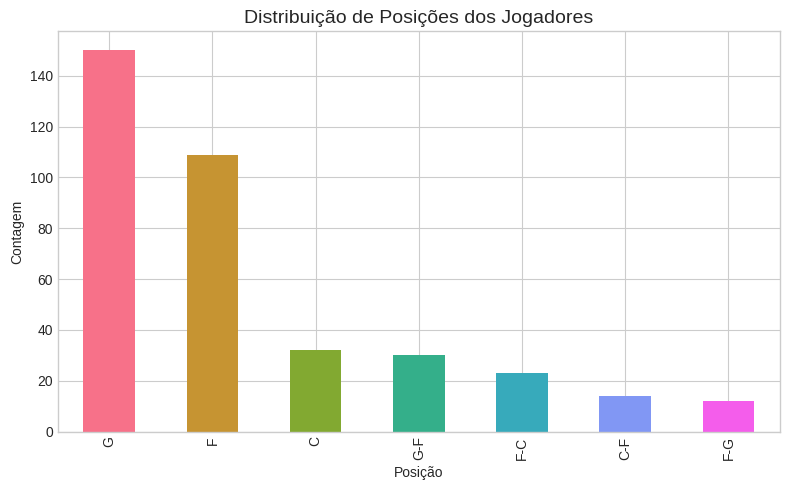

In [4]:
# Distribuição de posições
if 'POSITION' in df.columns:
    fig, ax = plt.subplots(figsize=(8, 5))
    df['POSITION'].value_counts().plot(kind='bar', ax=ax, color=sns.color_palette('husl', len(df['POSITION'].unique())))
    ax.set_title('Distribuição de Posições dos Jogadores', fontsize=14)
    ax.set_xlabel('Posição')
    ax.set_ylabel('Contagem')
    plt.tight_layout()
    plt.show()
else:
    print('Coluna POSITION não disponível')

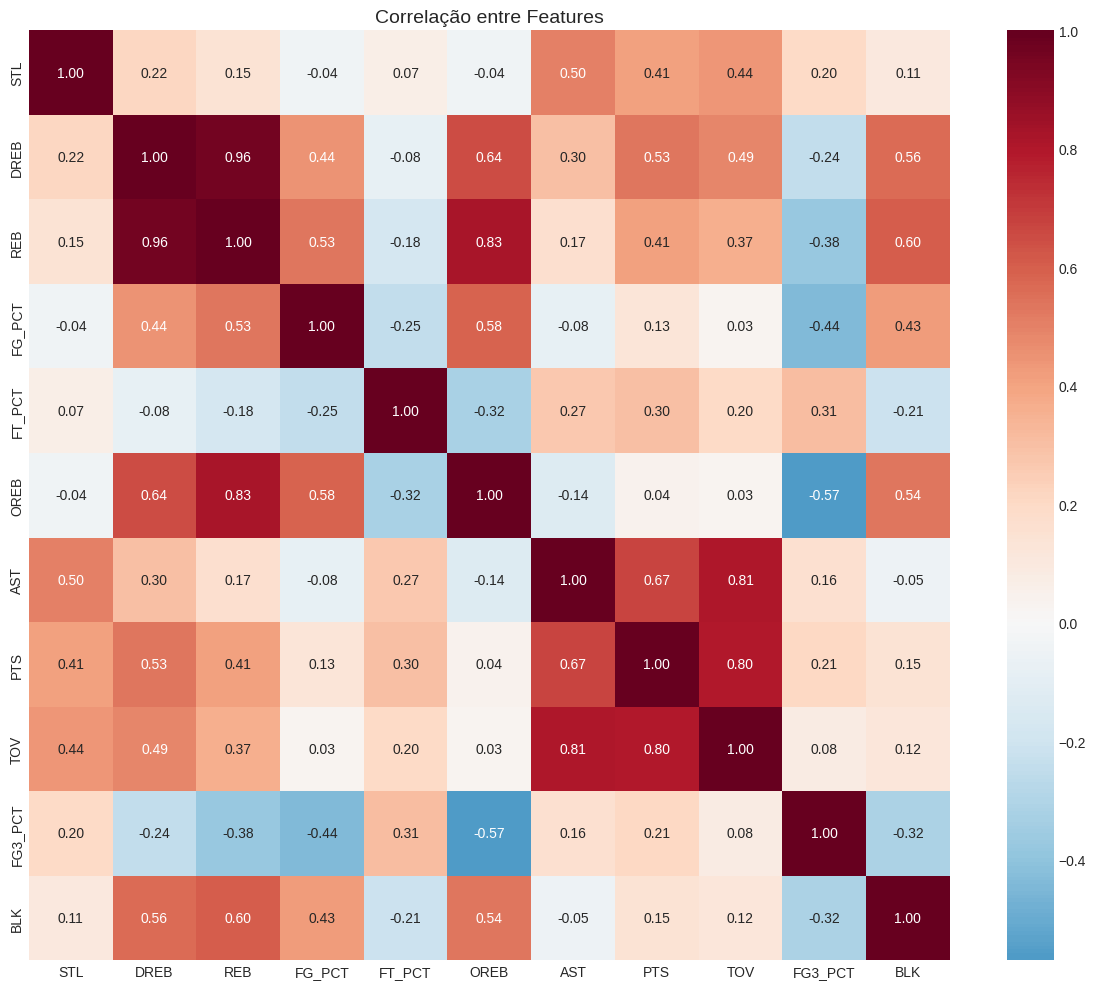

In [5]:
# Correlações entre features disponíveis
feature_candidates = [f for f in ALL_FEATURES + BASIC_FEATURES if f in df.columns]
feature_candidates = list(set(feature_candidates))

if len(feature_candidates) > 2:
    fig, ax = plt.subplots(figsize=(12, 10))
    corr = df[feature_candidates].corr()
    sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', center=0, ax=ax)
    ax.set_title('Correlação entre Features', fontsize=14)
    plt.tight_layout()
    plt.show()

## 4. Pré-processamento

In [6]:
# Normalização
X, df_meta, preprocessor = prepare_data(df)

print(f'\nFeatures utilizadas ({len(preprocessor.features_used)}):')
for f in preprocessor.features_used:
    print(f'  - {f}')

print(f'\nShape dos dados: {X.shape}')

# Posições para validação
positions = get_position_labels(df)
player_names = df['PLAYER_NAME'].tolist()

print(f'\nDistribuição de posições:')
unique, counts = np.unique(positions, return_counts=True)
for pos, count in zip(unique, counts):
    print(f'  {pos}: {count} ({count/len(positions)*100:.1f}%)')

PREPARAÇÃO DOS DADOS
Preprocessador ajustado: 370 amostras, 11 features
  Features: ['PTS', 'REB', 'OREB', 'DREB', 'AST', 'STL', 'BLK', 'FG_PCT', 'FG3_PCT', 'FT_PCT', 'TOV']
  Shape após normalização: (370, 11)

Features utilizadas (11):
  - PTS
  - REB
  - OREB
  - DREB
  - AST
  - STL
  - BLK
  - FG_PCT
  - FG3_PCT
  - FT_PCT
  - TOV

Shape dos dados: (370, 11)
Posições extraídas de 'POSITION_SIMPLE': 370/370 conhecidas

Distribuição de posições:
  Center: 46 (12.4%)
  Forward: 144 (38.9%)
  Guard: 180 (48.6%)


## 5. K-Means

In [7]:
# Ajustar K-Means
kmeans = KMeansClusterer()
kmeans.fit(X)
km_result = kmeans.get_best_result()

print(f'\nMelhor k: {km_result.k}')
print(f'Silhouette: {km_result.silhouette:.3f}')


K-MEANS CLUSTERING
  k= 3: Silhouette=0.303, Inertia=2366.7
  k= 4: Silhouette=0.277, Inertia=2114.2
  k= 5: Silhouette=0.206, Inertia=1918.3
  k= 6: Silhouette=0.174, Inertia=1788.7
  k= 7: Silhouette=0.175, Inertia=1675.6
  k= 8: Silhouette=0.170, Inertia=1599.9
  k= 9: Silhouette=0.171, Inertia=1518.5
  k=10: Silhouette=0.172, Inertia=1445.1
  k=11: Silhouette=0.171, Inertia=1394.6
  k=12: Silhouette=0.168, Inertia=1349.1

  Melhor k: 3 (Silhouette=0.303)

Melhor k: 3
Silhouette: 0.303


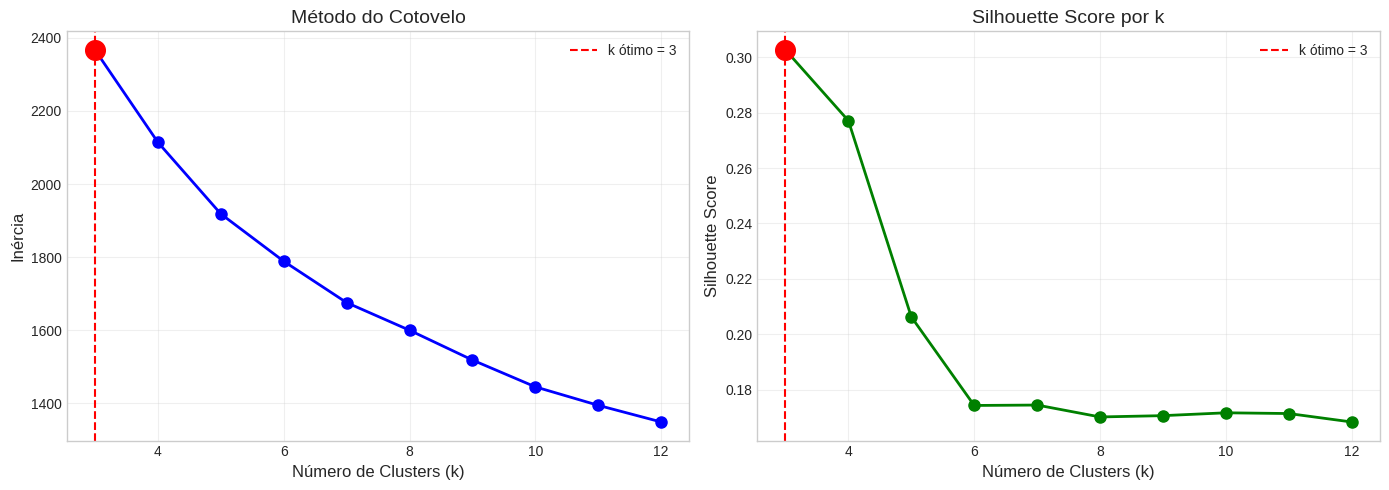

In [8]:
# Elbow curve
elbow = kmeans.get_elbow_data()
fig = plot_elbow_curve(
    elbow['k'].tolist(), elbow['inertia'].tolist(), elbow['silhouette'].tolist(),
    optimal_k=km_result.k
)
plt.show()

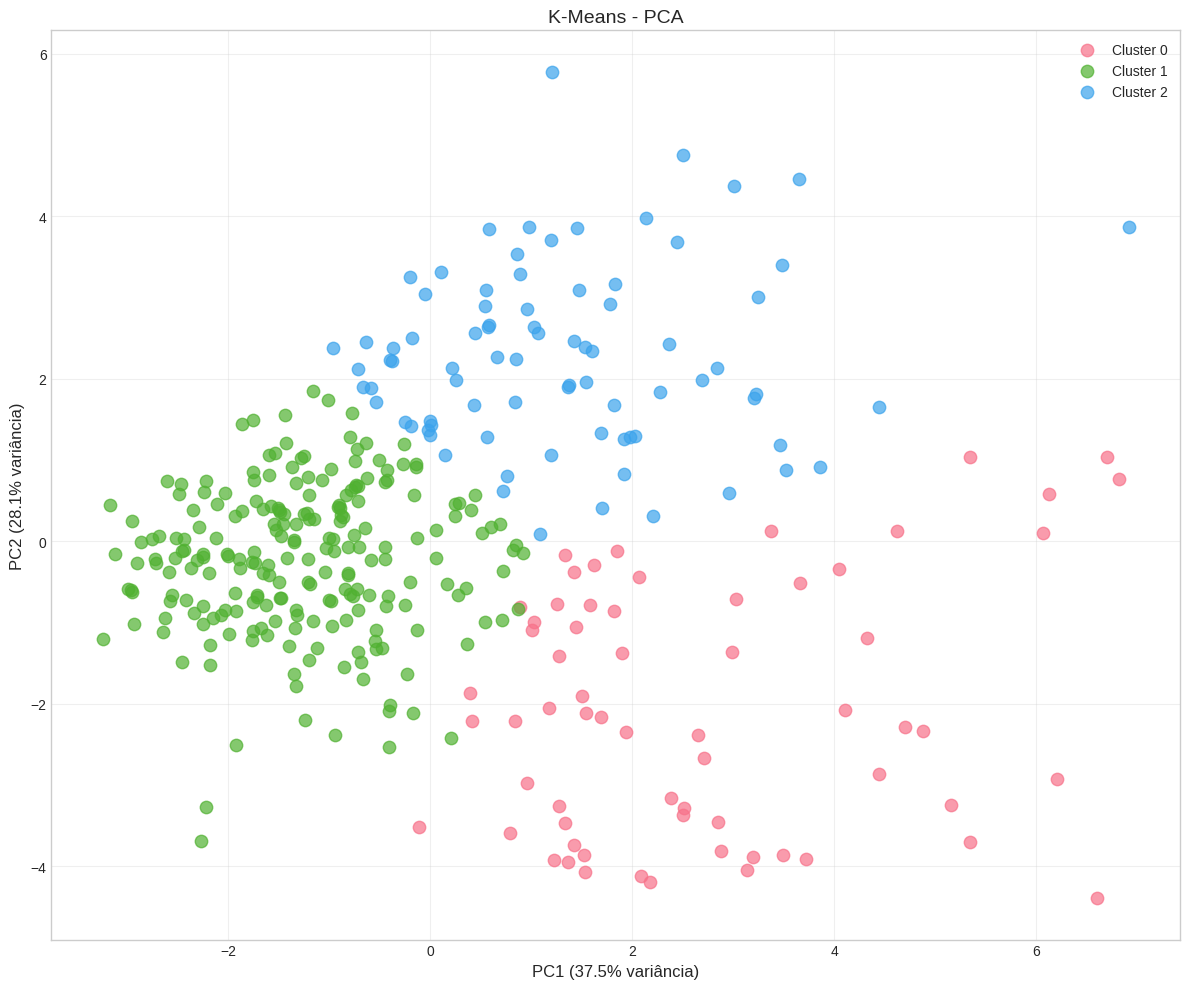

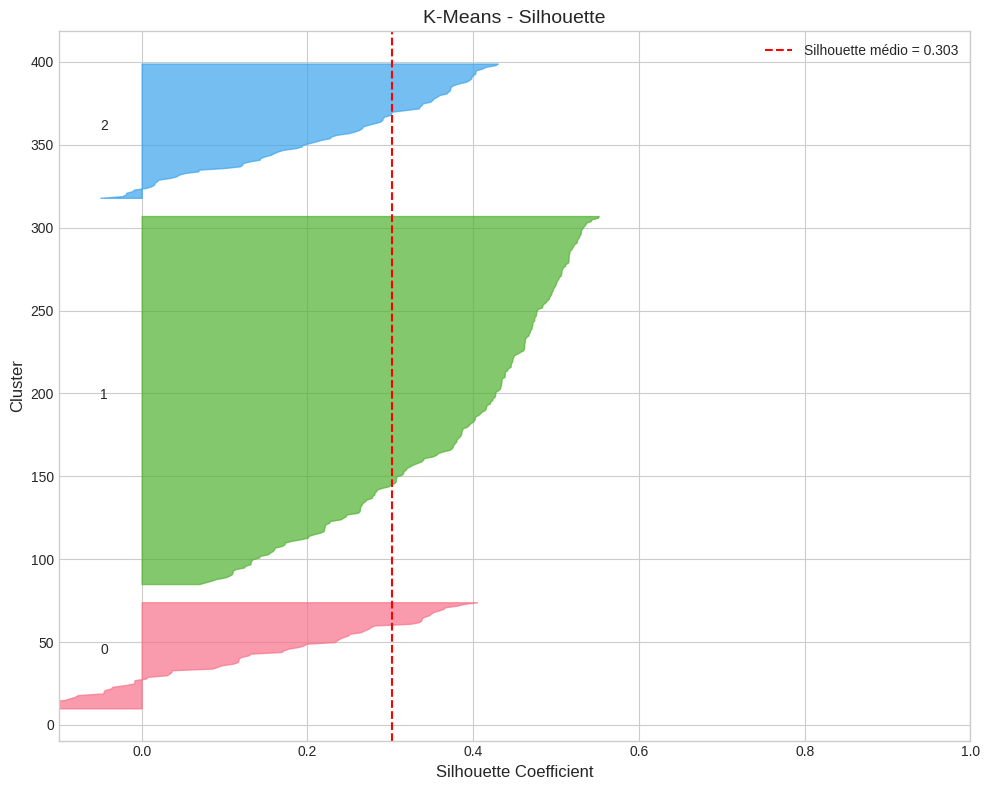

In [9]:
# PCA e Silhouette
fig = plot_clusters_2d(X, km_result.labels, title='K-Means - PCA', player_names=player_names)
plt.show()

fig = plot_silhouette_analysis(X, km_result.labels, title='K-Means - Silhouette')
plt.show()

## 6. GMM (Gaussian Mixture Models)

In [10]:
# Ajustar GMM
gmm = GMMClusterer()
gmm.fit(X)
gmm_result = gmm.get_best_result()

print(f'\nMelhor k: {gmm_result.k}')
print(f'Silhouette: {gmm_result.silhouette:.3f}')


GAUSSIAN MIXTURE MODELS (Soft Clustering)
  k= 3: Silhouette=0.219, BIC=6676.9
  k= 4: Silhouette=0.190, BIC=6715.6
  k= 5: Silhouette=0.149, BIC=6939.2
  k= 6: Silhouette=0.052, BIC=6496.4
  k= 7: Silhouette=0.091, BIC=7399.6
  k= 8: Silhouette=0.106, BIC=7571.4
  k= 9: Silhouette=0.077, BIC=7736.7
  k=10: Silhouette=0.108, BIC=7738.6
  k=11: Silhouette=0.102, BIC=8152.9
  k=12: Silhouette=-0.028, BIC=7823.9

  Melhor k: 3 (Silhouette=0.219)

Melhor k: 3
Silhouette: 0.219


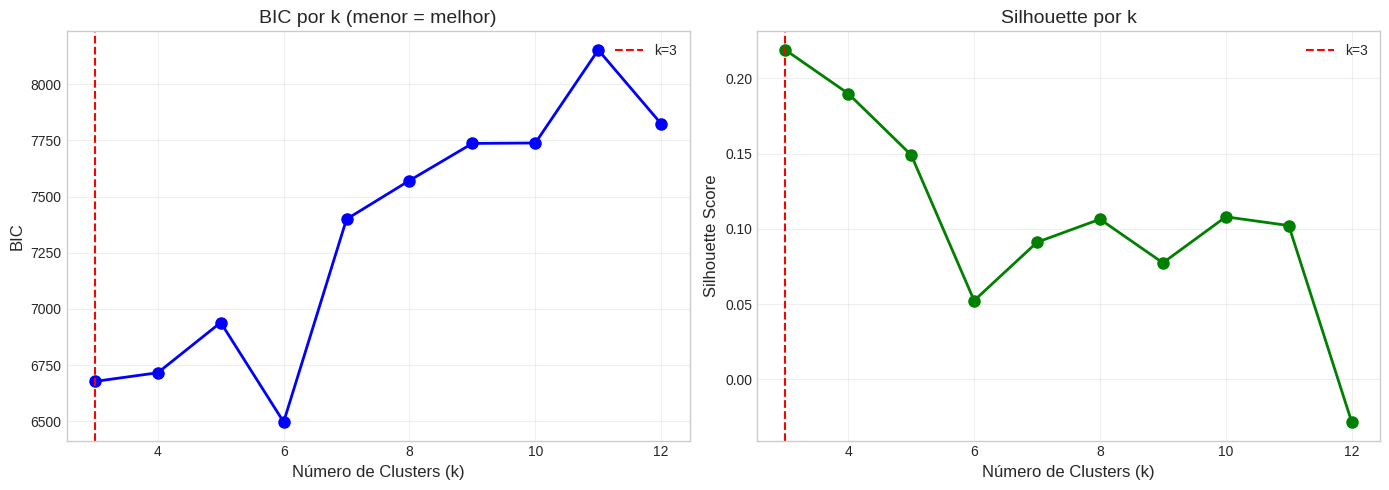

In [11]:
# BIC curve
bic_data = gmm.get_bic_data()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(bic_data['k'], bic_data['bic'], 'bo-', linewidth=2, markersize=8)
ax1.set_xlabel('Número de Clusters (k)', fontsize=12)
ax1.set_ylabel('BIC', fontsize=12)
ax1.set_title('BIC por k (menor = melhor)', fontsize=14)
ax1.axvline(x=gmm_result.k, color='r', linestyle='--', label=f'k={gmm_result.k}')
ax1.legend()
ax1.grid(True, alpha=0.3)

ax2.plot(bic_data['k'], bic_data['silhouette'], 'go-', linewidth=2, markersize=8)
ax2.set_xlabel('Número de Clusters (k)', fontsize=12)
ax2.set_ylabel('Silhouette Score', fontsize=12)
ax2.set_title('Silhouette por k', fontsize=14)
ax2.axvline(x=gmm_result.k, color='r', linestyle='--', label=f'k={gmm_result.k}')
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

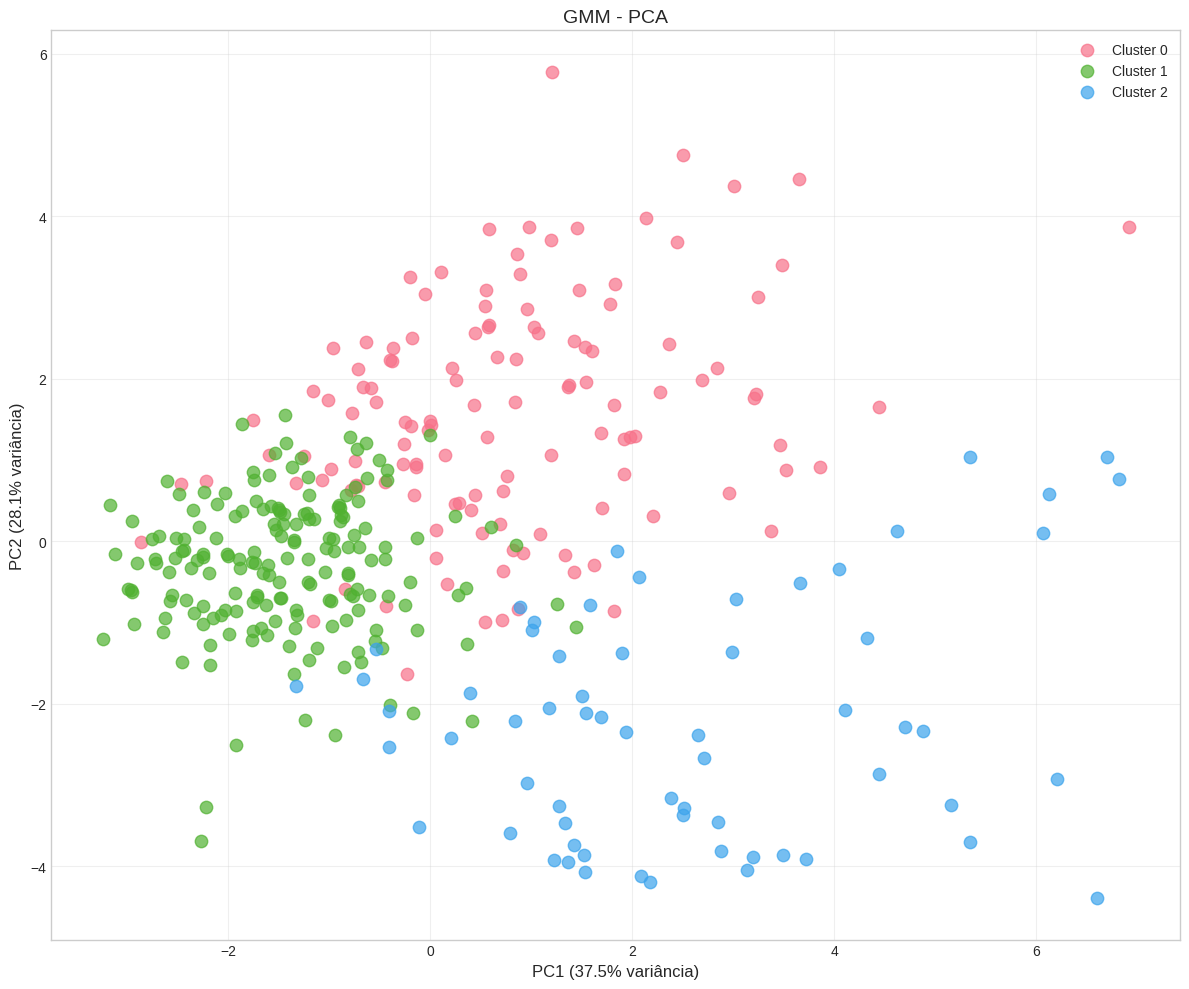

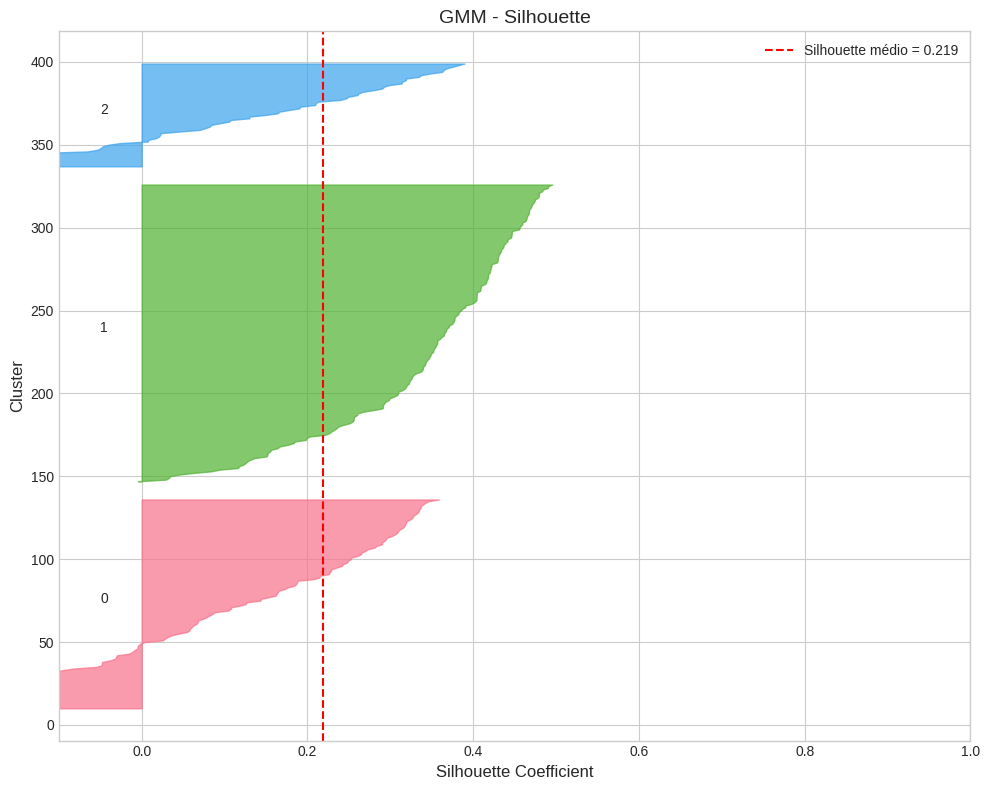

In [12]:
# PCA e Silhouette GMM
fig = plot_clusters_2d(X, gmm_result.labels, title='GMM - PCA', player_names=player_names)
plt.show()

fig = plot_silhouette_analysis(X, gmm_result.labels, title='GMM - Silhouette')
plt.show()

## 7. Clustering Hierárquico

In [13]:
# Ajustar Hierárquico
hier = HierarchicalClusterer()
hier.fit(X)
hier_result = hier.get_best_result()

print(f'\nMelhor k: {hier_result.k}')
print(f'Silhouette: {hier_result.silhouette:.3f}')


HIERARCHICAL CLUSTERING (linkage=ward)
  k= 3: Silhouette=0.294
  k= 4: Silhouette=0.284
  k= 5: Silhouette=0.135
  k= 6: Silhouette=0.140
  k= 7: Silhouette=0.135
  k= 8: Silhouette=0.139
  k= 9: Silhouette=0.139
  k=10: Silhouette=0.144
  k=11: Silhouette=0.141
  k=12: Silhouette=0.108

  Melhor k: 3 (Silhouette=0.294)

Melhor k: 3
Silhouette: 0.294


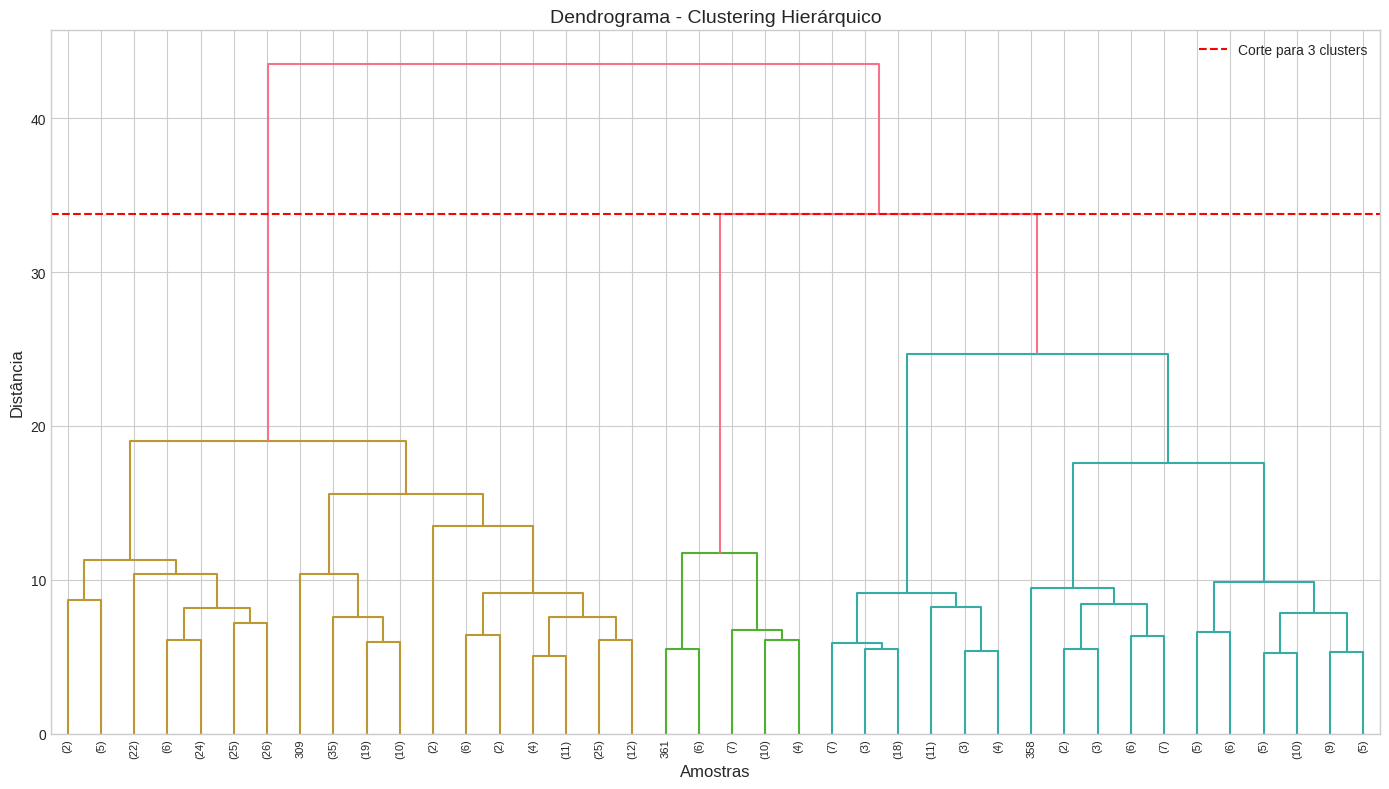

In [14]:
# Dendrograma
fig = plot_dendrogram(
    hier.linkage_matrix_,
    n_clusters=hier_result.k,
    p=40
)
plt.show()

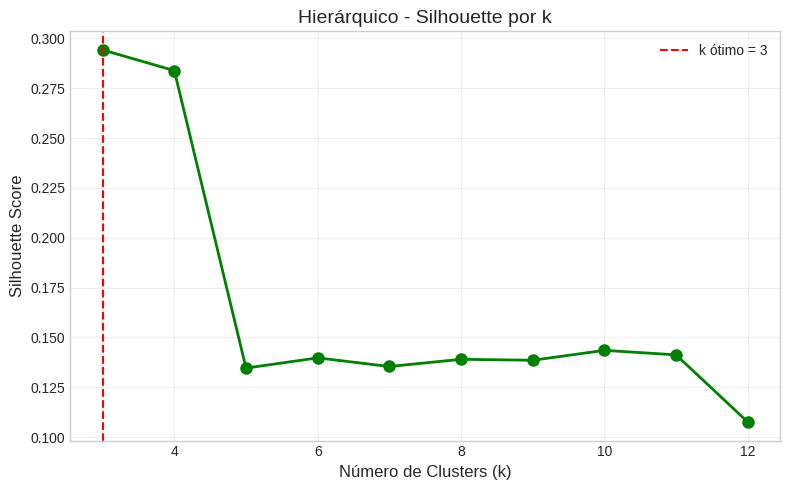

In [15]:
# Silhouette por k
sil_data = hier.get_silhouette_data()

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(sil_data['k'], sil_data['silhouette'], 'go-', linewidth=2, markersize=8)
ax.set_xlabel('Número de Clusters (k)', fontsize=12)
ax.set_ylabel('Silhouette Score', fontsize=12)
ax.set_title('Hierárquico - Silhouette por k', fontsize=14)
ax.axvline(x=hier_result.k, color='r', linestyle='--', label=f'k ótimo = {hier_result.k}')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

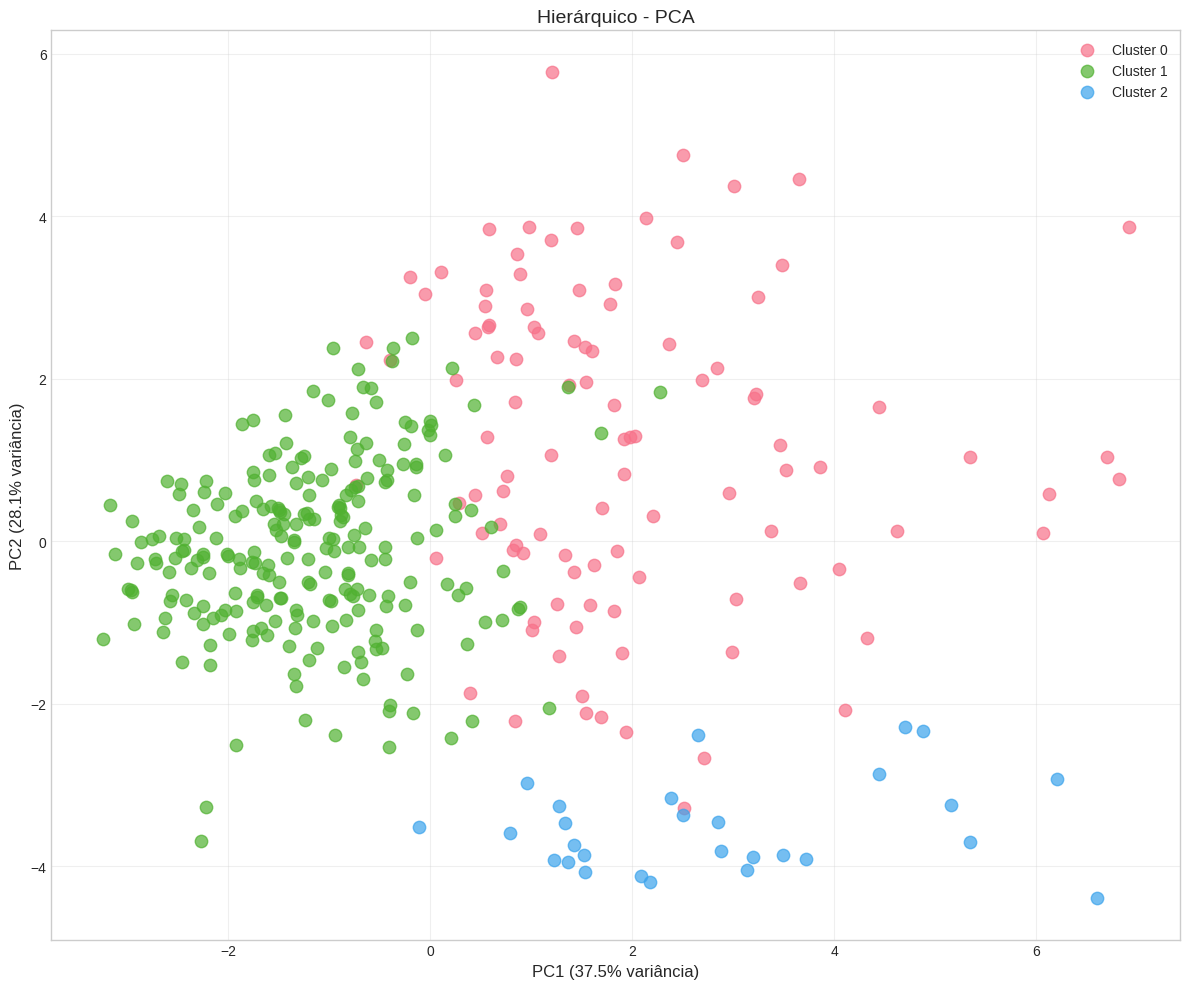

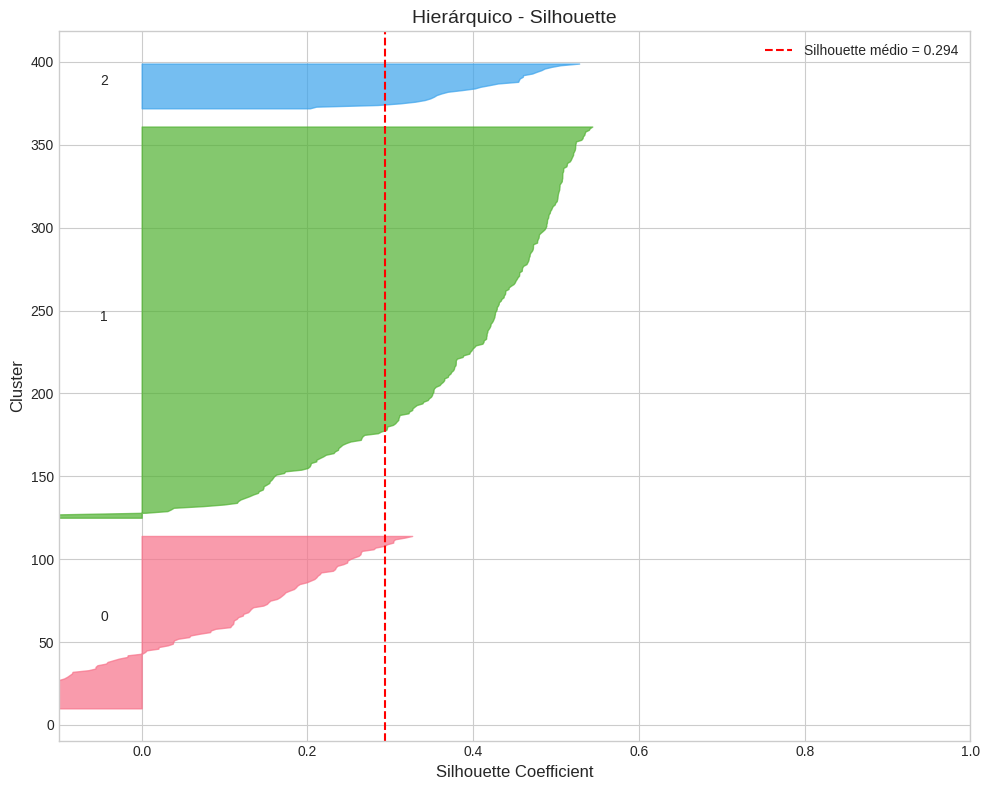

In [16]:
# PCA e Silhouette Hierárquico
fig = plot_clusters_2d(X, hier_result.labels, title='Hierárquico - PCA', player_names=player_names)
plt.show()

fig = plot_silhouette_analysis(X, hier_result.labels, title='Hierárquico - Silhouette')
plt.show()

## 8. Comparação de Algoritmos

In [17]:
# Tabela comparativa
comparison_df = compare_algorithms(
    X,
    {'kmeans': km_result, 'gmm': gmm_result, 'hierarchical': hier_result},
    positions,
)
comparison_df


COMPARAÇÃO DE ALGORITMOS

  Calculando estabilidade para kmeans...

  Calculando estabilidade para gmm...

  Calculando estabilidade para hierarchical...

   Algorithm  k  Silhouette Score  Davies-Bouldin Index  Calinski-Harabasz Index  ARI vs Positions  NMI vs Positions  Random Seed Mean ARI  Bootstrap Mean ARI  Mean Point Stability
     K-Means  3          0.302580              1.234239               132.061511          0.143543          0.183170              0.994372            0.839447              0.327850
         GMM  3          0.218854              1.496069               108.836796          0.129328          0.173672              0.875462            0.620391              0.374217
Hierarchical  3          0.294157              1.378995               109.044606          0.151024          0.149839              1.000000            0.529036              0.500550


,Algorithm,k,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index,ARI vs Positions,NMI vs Positions,Random Seed Mean ARI,Bootstrap Mean ARI,Mean Point Stability
0,K-Means,3,0.302580,1.234239,132.061511,0.143543,0.183170,0.994372,0.839447,0.327850
1,GMM,3,0.218854,1.496069,108.836796,0.129328,0.173672,0.875462,0.620391,0.374217
2,Hierarchical,3,0.294157,1.378995,109.044606,0.151024,0.149839,1.000000,0.529036,0.500550


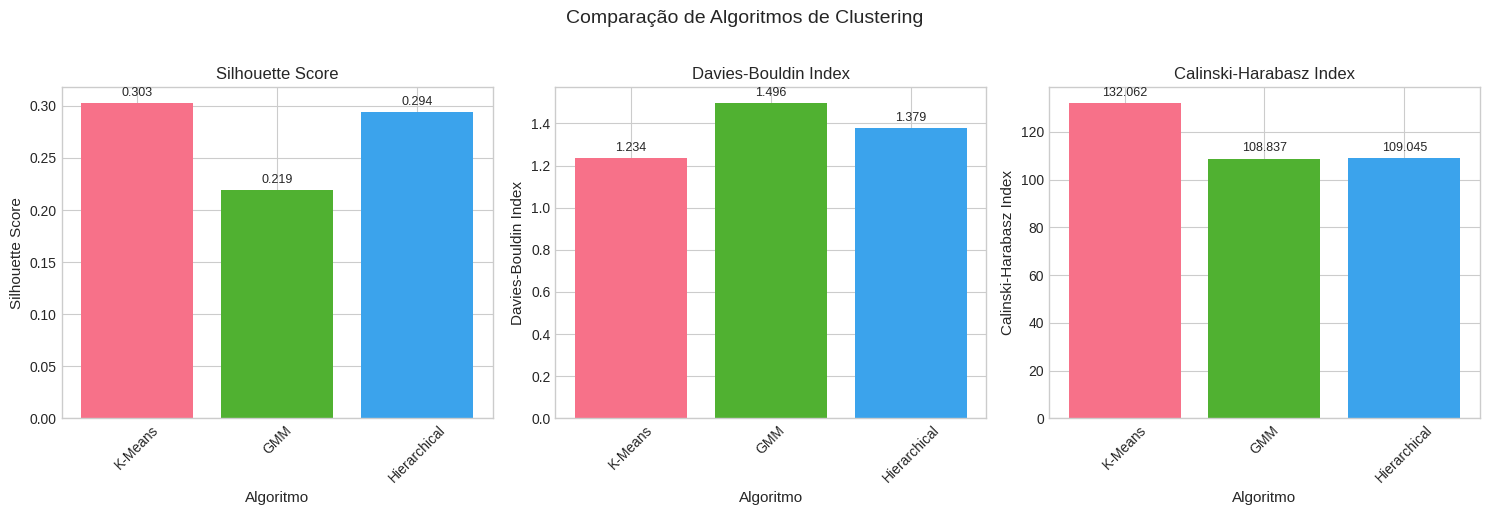

In [18]:
# Gráficos comparativos
fig = plot_algorithm_comparison(comparison_df)
plt.show()

## 9. Estabilidade

   Algorithm  Random Seed Mean ARI  Bootstrap Mean ARI  Mean Point Stability
     K-Means              0.994372            0.839447              0.327850
         GMM              0.875462            0.620391              0.374217
Hierarchical              1.000000            0.529036              0.500550


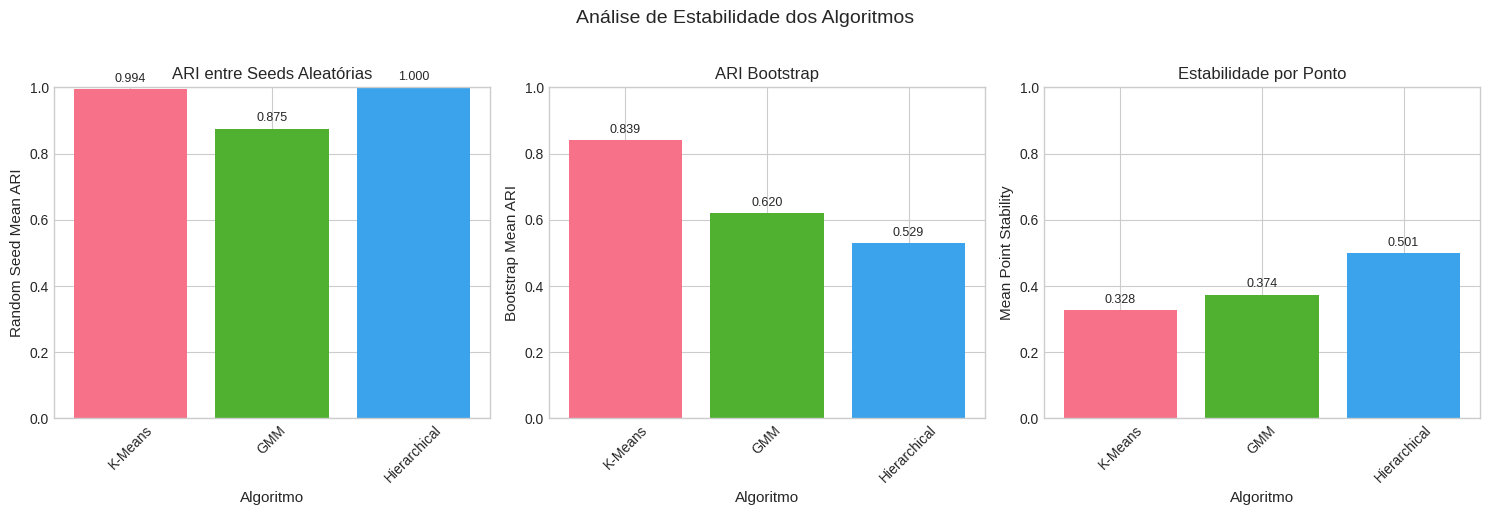

In [19]:
# Gráfico de estabilidade
stability_cols = ['Algorithm', 'Random Seed Mean ARI', 'Bootstrap Mean ARI', 'Mean Point Stability']
stability_df = comparison_df[stability_cols]
print(stability_df.to_string(index=False))

fig = plot_stability_comparison(stability_df)
plt.show()

## 10. Arquétipos e Crosstab vs Posições

In [20]:
# Perfis dos clusters (melhor algoritmo)
best_idx = comparison_df['Silhouette Score'].idxmax()
best_algo = comparison_df.loc[best_idx, 'Algorithm']
print(f'Melhor algoritmo (Silhouette): {best_algo}\n')

# Usar resultado correspondente
best_map = {'K-Means': km_result, 'GMM': gmm_result, 'Hierarchical': hier_result}
best_result = best_map[best_algo]

profiles = get_cluster_profiles(X, best_result.labels, preprocessor.features_used, df)
print(profiles.to_string(index=False))

# Exemplos
print(f'\nExemplos de Jogadores por Cluster ({best_algo}):')
examples = get_cluster_examples(best_result.labels, player_names, n_examples=7)
for cluster, players in examples.items():
    print(f'  Cluster {cluster}: {", ".join(players)}')

Melhor algoritmo (Silhouette): K-Means

 Cluster  N_Players       PTS      REB     OREB     DREB      AST      STL      BLK   FG_PCT  FG3_PCT   FT_PCT      TOV
       0         65 11.495385 7.772308 2.438462 5.336923 2.058462 0.730769 1.089231 0.569246 0.179369 0.695015 1.387692
       1        223  9.096413 3.445291 0.861883 2.585650 2.123318 0.771300 0.355157 0.437027 0.353229 0.772650 1.051570
       2         82 20.265854 5.354878 1.006098 4.353659 5.208537 1.195122 0.503659 0.460805 0.354720 0.817768 2.546341

Exemplos de Jogadores por Cluster (K-Means):
  Cluster 0: Adem Bona, Alex Sarr, Alperen Sengun, Amen Thompson, Andre Drummond, Anthony Davis, Ausar Thompson
  Cluster 1: A.J. Lawson, AJ Green, AJ Johnson, Aaron Gordon, Aaron Nesmith, Aaron Wiggins, Ajay Mitchell
  Cluster 2: Anfernee Simons, Anthony Edwards, Austin Reaves, Bam Adebayo, Bilal Coulibaly, Bradley Beal, Brandon Ingram


In [21]:
# Crosstab: Clusters vs Posições para cada algoritmo
for name, result in [('K-Means', km_result), ('GMM', gmm_result), ('Hierarchical', hier_result)]:
    ct = crosstab_clusters_positions(result.labels, positions, algorithm_name=name)
    print()


  Crosstab - K-Means:
Position  Center  Forward  Guard  All
Cluster                              
0             36       26      3   65
1              7       90    126  223
2              3       28     51   82
All           46      144    180  370


  Crosstab - GMM:
Position  Center  Forward  Guard  All
Cluster                              
0              8       47     72  127
1              3       72    105  180
2             35       25      3   63
All           46      144    180  370


  Crosstab - Hierarchical:
Position  Center  Forward  Guard  All
Cluster                              
0             23       46     36  105
1              6       87    144  237
2             17       11      0   28
All           46      144    180  370



## 11. Jogadores Híbridos (GMM)

In [22]:
# Jogadores híbridos identificados pelo GMM
if gmm_result.probabilities is not None:
    hybrids = analyze_hybrid_players(gmm_result.probabilities, player_names, threshold=0.25)
    print(f'{len(hybrids)} jogadores híbridos identificados (threshold=0.25):\n')
    if not hybrids.empty:
        display(hybrids.head(20))
    else:
        print('Nenhum jogador híbrido significativo.')
else:
    print('Probabilidades GMM não disponíveis.')

27 jogadores híbridos identificados (threshold=0.25):



,Player,Primary_Cluster,Primary_Prob,Secondary_Cluster,Secondary_Prob,Hybrid_Score
20,Matas Buzelis,0,0.507999,2,0.477958,0.969959
25,Spencer Dinwiddie,1,0.522397,0,0.477583,0.955186
6,Gradey Dick,0,0.523126,1,0.476811,0.953685
19,Marcus Garrett,1,0.528041,0,0.471928,0.943888
14,Jose Alvarado,1,0.530337,0,0.469663,0.939326
16,Klay Thompson,0,0.531931,1,0.467756,0.935825
21,Max Strus,1,0.540876,0,0.458769,0.917893
10,Jalen Smith,0,0.541038,1,0.384407,0.843369
0,Anthony Black,1,0.584987,0,0.415010,0.830023
3,Dillon Brooks,1,0.590858,0,0.408974,0.818116


## 12. Conclusão - Teste de Hipótese

In [23]:
# Ranking dos algoritmos
print('=' * 60)
print('RANKING DOS ALGORITMOS')
print('=' * 60)

print(f'\nPor Silhouette Score (maior = melhor):')
for _, row in comparison_df.sort_values('Silhouette Score', ascending=False).iterrows():
    print(f"  {row['Algorithm']}: {row['Silhouette Score']:.4f} (k={int(row['k'])})")

print(f'\nPor Davies-Bouldin (menor = melhor):')
for _, row in comparison_df.sort_values('Davies-Bouldin Index').iterrows():
    print(f"  {row['Algorithm']}: {row['Davies-Bouldin Index']:.4f}")

print(f'\nPor Calinski-Harabasz (maior = melhor):')
for _, row in comparison_df.sort_values('Calinski-Harabasz Index', ascending=False).iterrows():
    print(f"  {row['Algorithm']}: {row['Calinski-Harabasz Index']:.2f}")

print(f'\nPor Estabilidade Bootstrap (maior = melhor):')
for _, row in comparison_df.sort_values('Bootstrap Mean ARI', ascending=False).iterrows():
    print(f"  {row['Algorithm']}: {row['Bootstrap Mean ARI']:.4f}")

# Teste de hipótese
print('\n' + '=' * 60)
print('TESTE DE HIPÓTESE')
print('=' * 60)

best_sil = comparison_df.loc[comparison_df['Silhouette Score'].idxmax()]
best_db = comparison_df.loc[comparison_df['Davies-Bouldin Index'].idxmin()]
best_ch = comparison_df.loc[comparison_df['Calinski-Harabasz Index'].idxmax()]

winners = {best_sil['Algorithm'], best_db['Algorithm'], best_ch['Algorithm']}
sil_range = comparison_df['Silhouette Score'].max() - comparison_df['Silhouette Score'].min()
sil_mean = comparison_df['Silhouette Score'].mean()

print(f'\nH₀: Os três algoritmos produzem agrupamentos com qualidade equivalente.')
print(f'H₁: Existe diferença significativa na qualidade dos agrupamentos.\n')

if len(winners) == 1:
    winner = winners.pop()
    print(f'RESULTADO: H₀ REJEITADA')
    print(f'  {winner} supera os demais em todas as métricas internas.')
    print(f'  Diferença Silhouette: {sil_range:.4f} ({sil_range/sil_mean*100:.1f}% do valor médio)')
else:
    if sil_range > 0.05:
        print(f'RESULTADO: H₀ REJEITADA')
        print(f'  Diferenças significativas entre os algoritmos.')
    else:
        print(f'RESULTADO: H₀ NÃO REJEITADA')
        print(f'  As diferenças são pequenas.')

print(f'\nMELHOR ALGORITMO: {best_sil["Algorithm"]} '
      f'(k={int(best_sil["k"])}, Silhouette={best_sil["Silhouette Score"]:.4f})')

# Resumo do melhor
best_map = {'K-Means': km_result, 'GMM': gmm_result, 'Hierarchical': hier_result}
best_name = best_sil['Algorithm']
best_result = best_map[best_name]
val = validate_clustering(X, best_result.labels, positions, algorithm_name=best_name)
print(val.evidence_summary)

RANKING DOS ALGORITMOS

Por Silhouette Score (maior = melhor):
  K-Means: 0.3026 (k=3)
  Hierarchical: 0.2942 (k=3)
  GMM: 0.2189 (k=3)

Por Davies-Bouldin (menor = melhor):
  K-Means: 1.2342
  Hierarchical: 1.3790
  GMM: 1.4961

Por Calinski-Harabasz (maior = melhor):
  K-Means: 132.06
  Hierarchical: 109.04
  GMM: 108.84

Por Estabilidade Bootstrap (maior = melhor):
  K-Means: 0.8394
  GMM: 0.6204
  Hierarchical: 0.5290

TESTE DE HIPÓTESE

H₀: Os três algoritmos produzem agrupamentos com qualidade equivalente.
H₁: Existe diferença significativa na qualidade dos agrupamentos.

RESULTADO: H₀ REJEITADA
  K-Means supera os demais em todas as métricas internas.
  Diferença Silhouette: 0.0837 (30.8% do valor médio)

MELHOR ALGORITMO: K-Means (k=3, Silhouette=0.3026)

VALIDAÇÃO - K-Means

[1] Métricas Internas
    Silhouette Score:  0.3026
    Calinski-Harabasz: 132.06
    Davies-Bouldin:    1.2342
    Interpretação: estrutura razoável (Silhouette 0.303)

[2] Concordância com Posições Tradi